# Descriptive Data Analysis — Big Data Applications (China Firm-Year Panel)

**Objective:** profile the cleaned dataset, extract descriptive insights, and visualize patterns using pie, bar, horizontal bar, scatter, line, heatmap, boxplot, and histogram charts.

**Dataset:** `Big_Data_Applications_clean.csv` (firm-year observations). This notebook describes patterns in the supplied fields; confirm the substantive definitions of `TD`, `MD`, `BDA`, `IC`, `ADC`, `GI`, and `GP` against the project's data dictionary before interpreting them as specific business concepts.

**How to run:** place this notebook beside the CSV and run cells from top to bottom.

In [33]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10

DATA_PATH = Path("Big_Data_Applications_clean.csv")
if not DATA_PATH.exists():
    candidates = [Path("/mnt/data/Big_Data_Applications_clean.csv")]
    DATA_PATH = next((p for p in candidates if p.exists()), DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Loaded: Big_Data_Applications_clean.csv
Rows: 21,203 | Columns: 26


,firm_code,firm_code_str,year,province,province_name,region,industry_code,sector,TD,MD,...,MD_std,log_TD,log_MD,TD_share,TD_growth,MD_growth,BDA_change,n_years_observed,first_year,last_year
0,8,8,2015,110000,Beijing,East,C37,C,119,890,...,0,4.787492,6.792344,0.1337,NaN,NaN,NaN,9,2015,2023
1,8,8,2016,110000,Beijing,East,C37,C,98,691,...,0,4.595120,6.539586,0.1418,-0.1765,-0.2236,0.0,9,2015,2023
2,8,8,2017,110000,Beijing,East,C37,C,133,978,...,0,4.897840,6.886532,0.1360,0.3571,0.4153,1.0,9,2015,2023
3,8,8,2018,110000,Beijing,East,C37,C,97,722,...,0,4.584967,6.583409,0.1343,-0.2707,-0.2618,0.0,9,2015,2023
4,8,8,2019,110000,Beijing,East,C37,C,173,1309,...,0,5.159055,7.177782,0.1322,0.7835,0.8130,0.0,9,2015,2023


## 1. Dataset structure and quality

In [34]:
print("Shape:", df.shape)
print("Year range:", int(df["year"].min()), "to", int(df["year"].max()))
print("Unique firms:", df["firm_code"].nunique())
print("Provinces:", df["province_name"].nunique())
print("Regions:", df["region"].nunique())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
}).sort_values("missing_values", ascending=False))
print("Exact duplicate rows:", int(df.duplicated().sum()))
if {"firm_code", "year"}.issubset(df.columns):
    print("Duplicate firm-year keys:", int(df.duplicated(["firm_code", "year"]).sum()))
display(df.describe(include="all").T)

Shape: (21203, 26)
Year range: 2014 to 2023
Unique firms: 3514
Provinces: 31
Regions: 4


,dtype,missing_values,missing_pct,unique_values
BDA_change,float64,3514,16.57,8
MD_growth,float64,3514,16.57,11280
TD_growth,float64,3514,16.57,6181
firm_code,int64,0,0.00,3514
firm_code_str,int64,0,0.00,3514
first_year,int64,0,0.00,10
n_years_observed,int64,0,0.00,10
TD_share,float64,0,0.00,659
log_MD,float64,0,0.00,3251
log_TD,float64,0,0.00,1007


Exact duplicate rows: 0
Duplicate firm-year keys: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
firm_code,21203.0,NaN,NaN,NaN,319611.318021,272861.579349,8.0,2540.0,300527.0,600893.0,873726.0
firm_code_str,21203.0,NaN,NaN,NaN,319611.318021,272861.579349,8.0,2540.0,300527.0,600893.0,873726.0
year,21203.0,NaN,NaN,NaN,2019.405603,2.792613,2014.0,2017.0,2020.0,2022.0,2023.0
province,21203.0,NaN,NaN,NaN,356089.704287,111319.511528,110000.0,320000.0,340000.0,440000.0,650000.0
province_name,21203,31,Guangdong,3596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,21203,4,East,15091,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry_code,21203,32,C39,3325,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector,21203,4,C,21200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TD,21203.0,NaN,NaN,NaN,121.375324,265.142174,1.0,18.0,43.0,104.0,1942.0
MD,21203.0,NaN,NaN,NaN,883.702919,1950.089379,8.0,129.0,313.0,760.0,14499.0


## 2. Executive descriptive insights

In [35]:
n_rows, n_cols = df.shape
n_firms = df["firm_code"].nunique() if "firm_code" in df else np.nan
year_min, year_max = int(df["year"].min()), int(df["year"].max())
top_province = df["province_name"].value_counts().idxmax() if "province_name" in df else "N/A"
top_province_n = int(df["province_name"].value_counts().max()) if "province_name" in df else 0
top_region = df["region"].value_counts().idxmax() if "region" in df else "N/A"
top_sector = df["sector"].value_counts().idxmax() if "sector" in df else "N/A"

display(Markdown(f'''
### Dataset at a glance
- **{n_rows:,} observations** and **{n_cols} columns**.
- **{n_firms:,} unique firms** represented across **{year_min}–{year_max}**.
- The most frequently represented province is **{top_province}** ({top_province_n:,} rows).
- The most represented region is **{top_region}**; the most represented sector code is **{top_sector}**.
- Missing values in growth/change variables may be expected where a prior year is unavailable; investigate before imputing or dropping them.
'''))

numeric = df.select_dtypes(include=np.number)
if "year" in df:
    annual_counts = df.groupby("year").size()
    display(Markdown(f"- Annual observations range from **{annual_counts.min():,}** to **{annual_counts.max():,}**; highest count is in **{int(annual_counts.idxmax())}**."))
if "TD" in df:
    display(Markdown(f"- `TD` has median **{df['TD'].median():,.2f}** and mean **{df['TD'].mean():,.2f}**. A mean notably above the median suggests a right-skewed distribution or high-value observations."))
if "MD" in df:
    display(Markdown(f"- `MD` has median **{df['MD'].median():,.2f}** and mean **{df['MD'].mean():,.2f}**."))


### Dataset at a glance
- **21,203 observations** and **26 columns**.
- **3,514 unique firms** represented across **2014–2023**.
- The most frequently represented province is **Guangdong** (3,596 rows).
- The most represented region is **East**; the most represented sector code is **C**.
- Missing values in growth/change variables may be expected where a prior year is unavailable; investigate before imputing or dropping them.


- Annual observations range from **1,253** to **3,328**; highest count is in **2023**.

- `TD` has median **43.00** and mean **121.38**. A mean notably above the median suggests a right-skewed distribution or high-value observations.

- `MD` has median **313.00** and mean **883.70**.

## 3. Categorical composition — pie chart

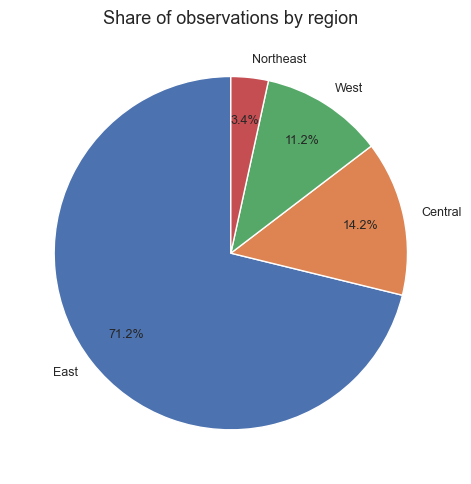

,observations,share_pct
region,,
East,15091,71.17
Central,3010,14.20
West,2377,11.21
Northeast,725,3.42


In [36]:
category = "region" if "region" in df else "sector"
counts = df[category].value_counts()
plt.figure(figsize=(10, 5))
plt.pie(counts.values, labels=counts.index.astype(str), autopct="%1.1f%%", startangle=90,
        pctdistance=0.75, textprops={"fontsize": 9})
plt.title(f"Share of observations by {category}")
plt.tight_layout()
plt.show()
display(counts.rename("observations").to_frame().assign(share_pct=(counts / counts.sum() * 100).round(2)))

## 4. Observations by year — bar chart

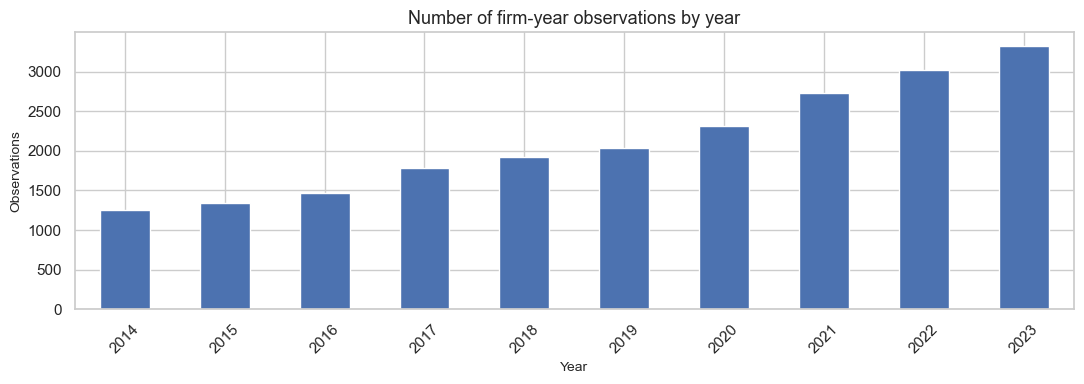

,observations
year,
2014,1253
2015,1346
2016,1472
2017,1782
2018,1921
2019,2035
2020,2318
2021,2724
2022,3024


In [37]:
year_counts = df.groupby("year").size().sort_index()
ax = year_counts.plot(kind="bar", figsize=(11, 4))
ax.set(title="Number of firm-year observations by year", xlabel="Year", ylabel="Observations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(year_counts.rename("observations").to_frame())

## 5. Province comparison — horizontal bar chart

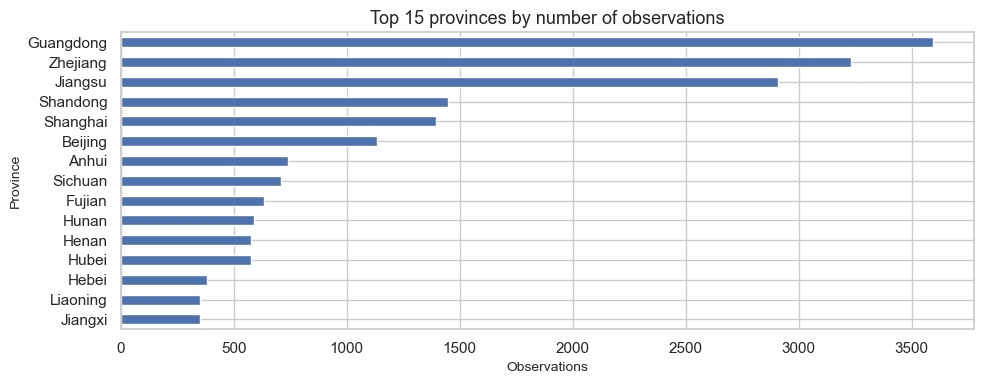

,observations
province_name,
Guangdong,3596
Zhejiang,3231
Jiangsu,2910
Shandong,1448
Shanghai,1397
Beijing,1136
Anhui,742
Sichuan,708
Fujian,635


In [38]:
province_col = "province_name"
province_counts = df[province_col].value_counts().head(15).sort_values()
ax = province_counts.plot(kind="barh", figsize=(10, 4))
ax.set(title="Top 15 provinces by number of observations", xlabel="Observations", ylabel="Province")
plt.tight_layout()
plt.show()
display(province_counts.sort_values(ascending=False).rename("observations").to_frame())

## 6. Time trend — line chart

,TD,MD,BDA,IC,ADC,GI,GP
year,,,,,,,
2014,98.753,716.831,3.955,0.179,-1.057,0.054,1.488
2015,103.823,753.935,3.749,0.185,-1.027,0.057,1.756
2016,110.804,804.431,3.923,0.186,-1.018,0.058,1.863
2017,110.265,800.958,4.137,0.191,-1.021,0.066,1.762
2018,124.645,906.474,4.184,0.204,-1.006,0.066,1.757
2019,135.406,984.939,4.271,0.231,-1.007,0.083,1.678
2020,138.579,1007.250,4.364,0.248,-0.999,0.077,1.651
2021,130.637,951.018,4.429,0.252,-1.005,0.047,1.802
2022,124.727,908.873,4.435,0.290,-1.009,0.045,1.879


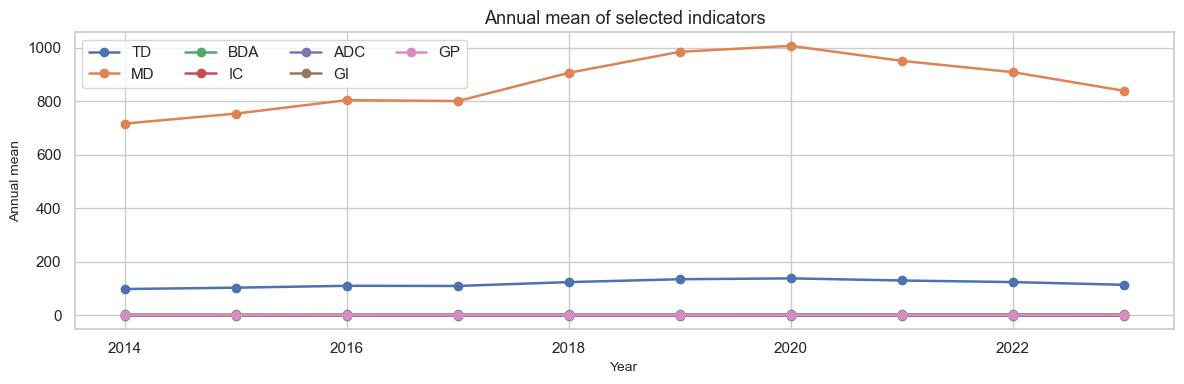

In [39]:
metrics = [c for c in ["TD", "MD", "BDA", "IC", "ADC", "GI", "GP"] if c in df.columns]
annual = df.groupby("year")[metrics].mean(numeric_only=True)
display(annual.round(3))
fig, ax = plt.subplots(figsize=(12, 4))
for col in metrics:
    ax.plot(annual.index, annual[col], marker="o", linewidth=1.8, label=col)
ax.set(title="Annual mean of selected indicators", xlabel="Year", ylabel="Annual mean")
ax.legend(ncol=4, frameon=True)
plt.tight_layout()
plt.show()

## 7. Relationship between two numeric variables — scatter plot

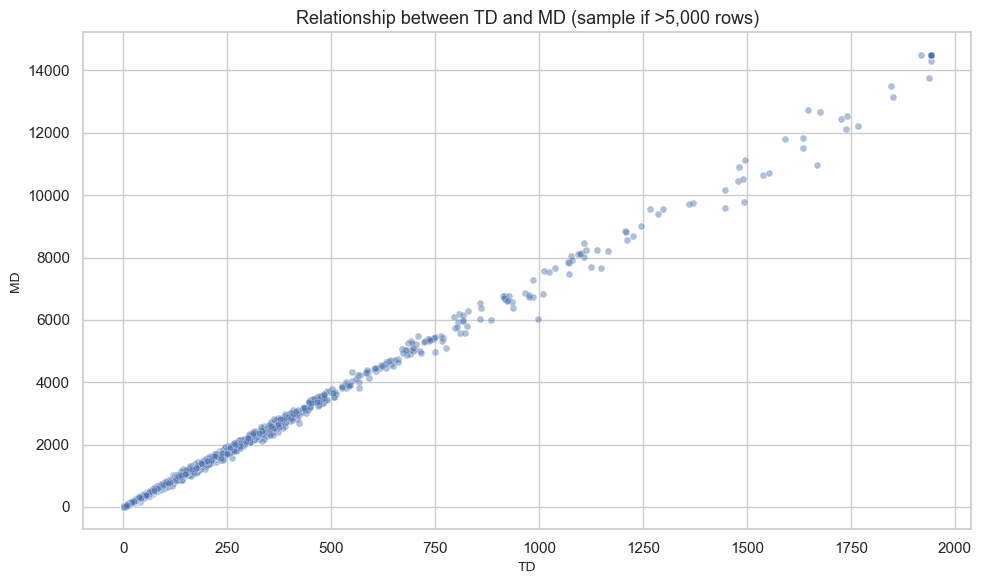

Pearson correlation (TD, MD): 0.999


In [40]:
x_col, y_col = ("TD", "MD") if {"TD", "MD"}.issubset(df.columns) else (numeric.columns[0], numeric.columns[1])
plot_df = df[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
# Use a sample for responsiveness if the dataset is large; fixed random_state makes it reproducible.
if len(plot_df) > 5000:
    plot_df = plot_df.sample(5000, random_state=42)
sns.scatterplot(data=plot_df, x=x_col, y=y_col, alpha=0.45, s=25)
plt.title(f"Relationship between {x_col} and {y_col} (sample if >5,000 rows)")
plt.tight_layout()
plt.show()
print(f"Pearson correlation ({x_col}, {y_col}): {df[[x_col, y_col]].corr().iloc[0,1]:.3f}")

## 8. Correlation heatmap

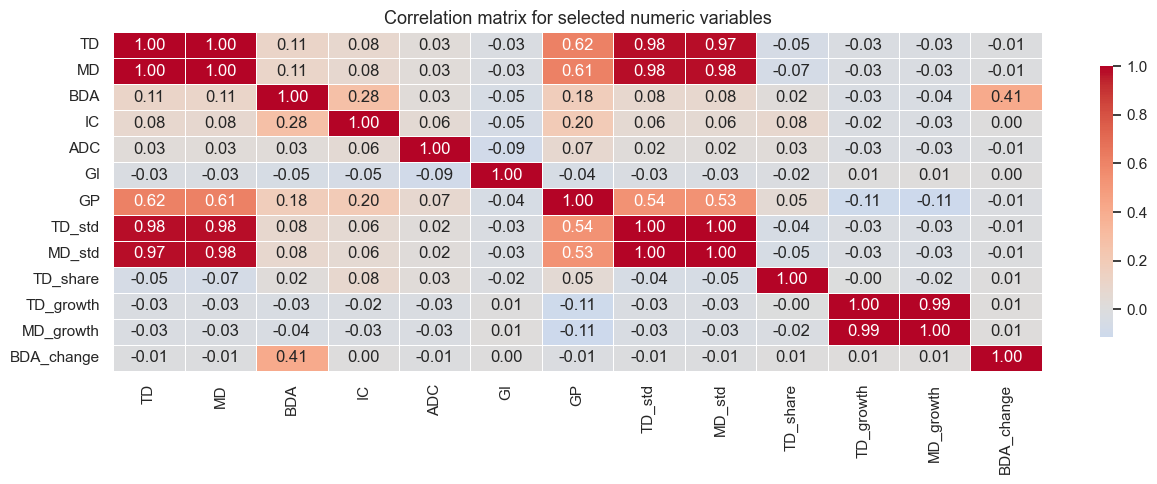

In [46]:
corr_cols = [c for c in ["TD", "MD", "BDA", "IC", "ADC", "GI", "GP", "TD_std", "MD_std",
                          "TD_share", "TD_growth", "MD_growth", "BDA_change"] if c in df.columns]
corr = df[corr_cols].corr(numeric_only=True)
plt.figure(figsize=(13, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False,
            linewidths=0.4, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix for selected numeric variables")
plt.tight_layout()
plt.show()

## 9. Distribution and outliers — boxplot

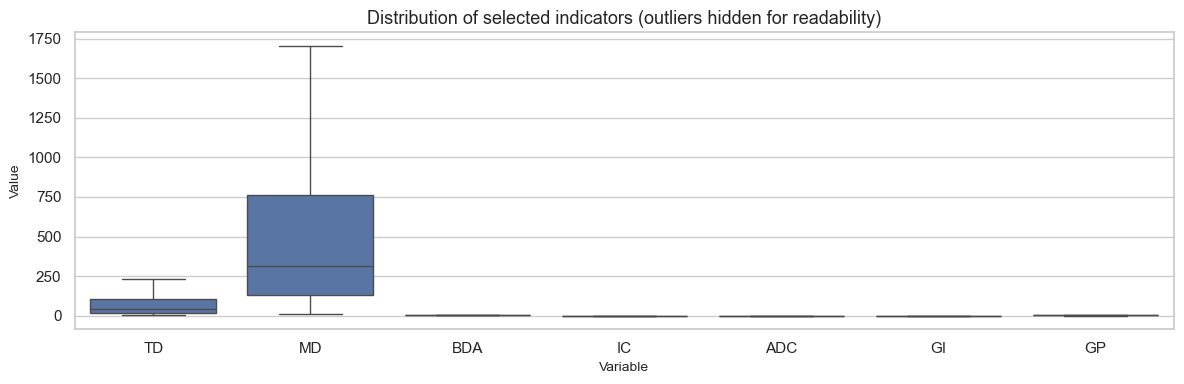

,min,25%,50%,75%,max,mean,std
TD,1.0,18.0,43.0,104.0,1942.0,121.375,265.142
MD,8.0,129.0,313.0,760.0,14499.0,883.703,1950.089
BDA,1.0,4.0,4.0,5.0,7.0,4.274,0.552
IC,0.0,0.0,0.0,0.0,2.0,0.242,0.445
ADC,-2.0,-1.0,-1.0,-1.0,0.0,-1.013,0.335
GI,0.0,0.0,0.0,0.0,1.0,0.059,0.235
GP,0.0,1.0,2.0,3.0,8.0,1.806,1.362


In [42]:
box_cols = [c for c in ["TD", "MD", "BDA", "IC", "ADC", "GI", "GP"] if c in df.columns]
long_box = df[box_cols].melt(var_name="variable", value_name="value")
plt.figure(figsize=(12, 4))
sns.boxplot(data=long_box, x="variable", y="value", showfliers=False)
plt.title("Distribution of selected indicators (outliers hidden for readability)")
plt.xlabel("Variable")
plt.ylabel("Value")
plt.tight_layout()
plt.show()
display(df[box_cols].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(3))

## 10. Frequency distribution — histogram

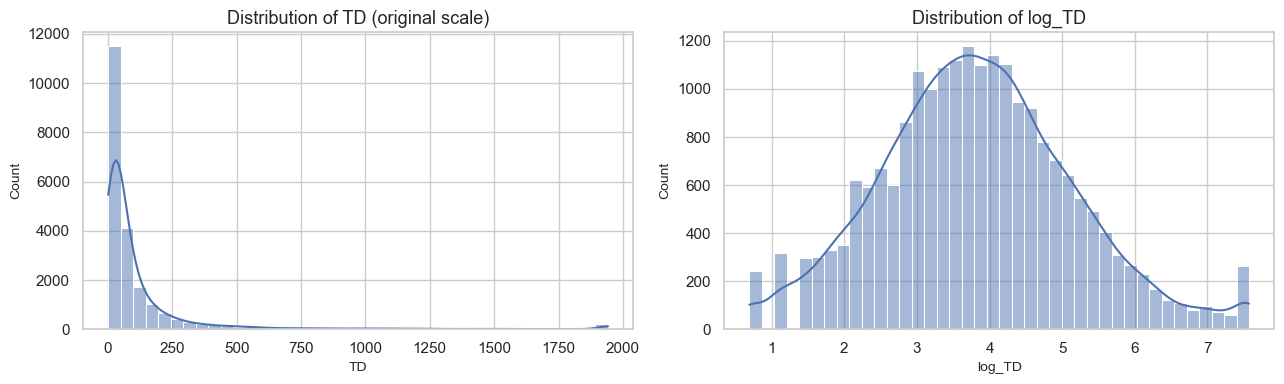

In [43]:
hist_col = "TD" if "TD" in df.columns else numeric.columns[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[hist_col].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title(f"Distribution of {hist_col} (original scale)")
axes[0].set_xlabel(hist_col)
log_col = "log_TD" if "log_TD" in df.columns else None
if log_col:
    sns.histplot(df[log_col].dropna(), bins=40, kde=True, ax=axes[1])
    axes[1].set_title(f"Distribution of {log_col}")
    axes[1].set_xlabel(log_col)
else:
    axes[1].axis("off")
plt.tight_layout()
plt.show()

## 11. Sector and regional comparisons

,observations,mean_TD,median_TD,mean_MD
sector,,,,
C,21200,121.38,43.0,883.741
A,1,23.00,23.0,181.000
E,1,34.00,34.0,259.000
F,1,198.00,198.0,1394.000


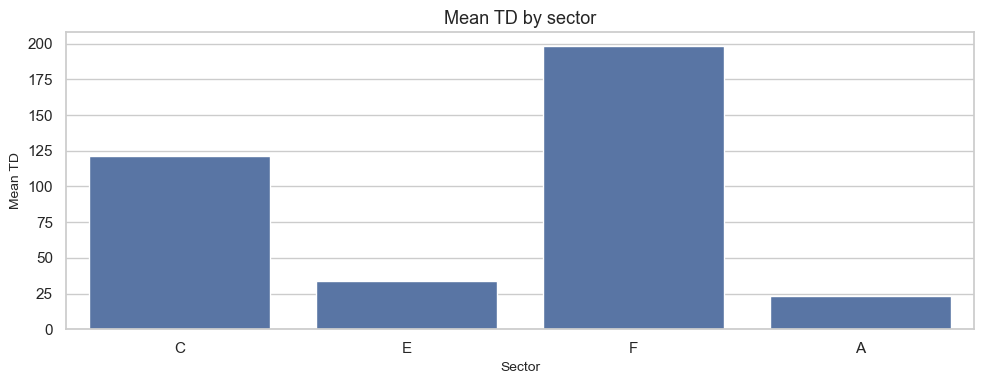

,TD,MD,BDA
region,,,
Central,123.053,895.493,4.234
East,124.834,908.462,4.299
Northeast,93.412,682.028,4.128
West,105.821,773.093,4.210


In [44]:
if {"sector", "TD"}.issubset(df.columns):
    sector_summary = df.groupby("sector").agg(
        observations=("TD", "size"), mean_TD=("TD", "mean"), median_TD=("TD", "median"),
        mean_MD=("MD", "mean") if "MD" in df.columns else ("TD", "mean")
    ).sort_values("observations", ascending=False)
    display(sector_summary.round(3))
    plt.figure(figsize=(10, 4))
    sns.barplot(data=df, x="sector", y="TD", estimator=np.mean, errorbar=None)
    plt.title("Mean TD by sector")
    plt.xlabel("Sector")
    plt.ylabel("Mean TD")
    plt.tight_layout()
    plt.show()

if {"region", "TD"}.issubset(df.columns):
    display(df.groupby("region")[["TD", "MD", "BDA"]].mean(numeric_only=True).round(3))

## 12. Growth and change metrics

TD_growth: n=17,689, mean=0.491, median=0.064, positive=53.8%, negative=42.8%, zero=3.4%


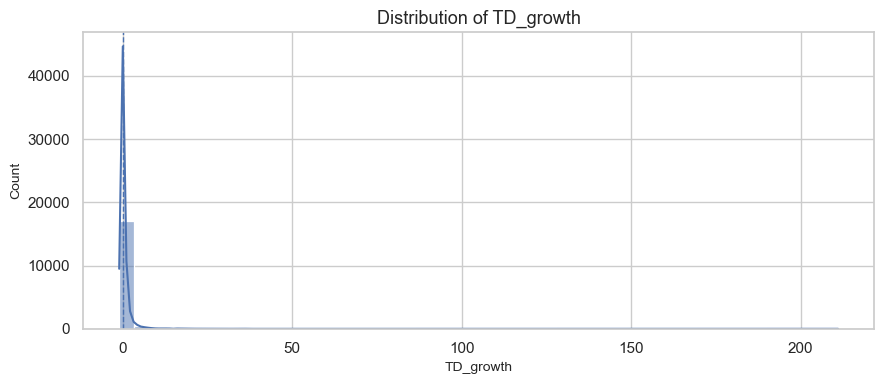

MD_growth: n=17,689, mean=0.494, median=0.068, positive=55.1%, negative=43.6%, zero=1.4%


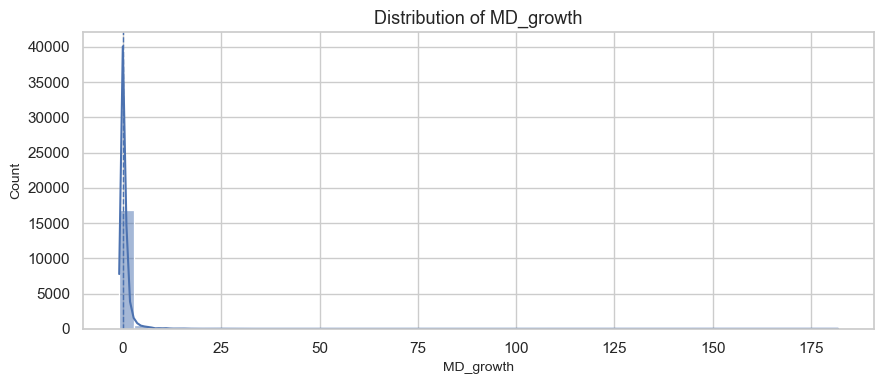

BDA_change: n=17,689, mean=0.083, median=0.000, positive=13.1%, negative=4.8%, zero=82.0%


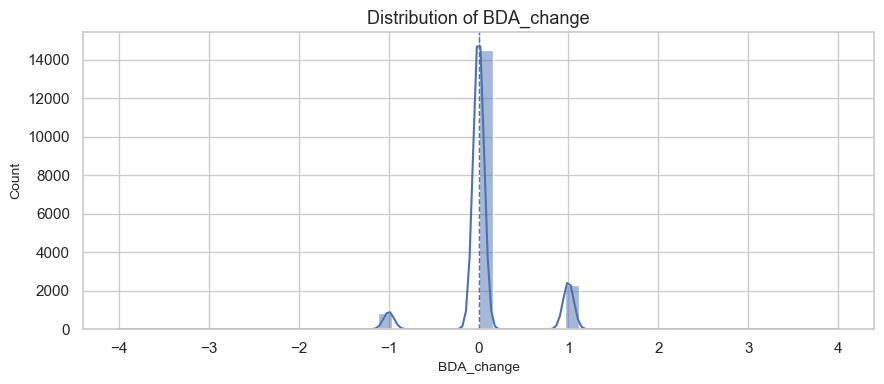

In [45]:
for col in ["TD_growth", "MD_growth", "BDA_change"]:
    if col in df.columns:
        s = df[col].dropna()
        print(f"{col}: n={len(s):,}, mean={s.mean():.3f}, median={s.median():.3f}, "
              f"positive={(s > 0).mean()*100:.1f}%, negative={(s < 0).mean()*100:.1f}%, zero={(s == 0).mean()*100:.1f}%")
        plt.figure(figsize=(9, 4))
        sns.histplot(s, bins=50, kde=True)
        plt.axvline(0, linestyle="--", linewidth=1)
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()

## 13. Analyst conclusions and recommended next steps

Use the figures and summary tables above to complete a defensible narrative. In particular:

1. **Coverage:** verify whether observations are balanced across years, provinces, and sectors; differences in row counts can affect comparisons.
2. **Concentration:** compare the leading provinces/regions/sectors with the rest, and avoid treating observation share as a measure of economic importance.
3. **Trend:** inspect annual means and medians together. Changes in composition can create apparent trends even when individual firms do not change.
4. **Skew and outliers:** compare the original-scale histogram with `log_TD`/`log_MD` and review boxplots before choosing summary statistics.
5. **Relationships:** correlation is descriptive, not causal. Large correlations may reflect scale, time trends, or sector/province composition.
6. **Panel structure:** where possible, compare within-firm changes over time and check how many years each firm is observed.
7. **Definitions:** interpret `TD`, `MD`, `BDA`, `IC`, `ADC`, `GI`, and `GP` only after confirming their exact definitions in the project's data dictionary.

**Suggested follow-up analysis:** firm-level trend trajectories, province × year heatmap, sector-adjusted comparisons, and robust summaries (median/IQR) alongside means.